<a href="https://colab.research.google.com/github/mrniktarasov/12-medical-image-analysis/blob/feature%2Feda-data/notebooks/vitaly_eda_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Часть 1. Данные и разбиение (Виталий)

Ноутбук готовит данные для всей команды: скачивает набор Retinal OCT (Kermany et al., Mendeley Data v3), собирает таблицу снимков, проверяет баланс классов, ищет битые файлы и дубли и делает разбиение train/val/test без утечки по пациентам.

**Результаты, которыми пользуется команда**

| Файл | Что внутри |
|---|---|
| `data/metadata.csv` | все 109 309 снимков: путь, выборка, класс, пациент, размер, режим, вес файла |
| `data/splits.csv` | итоговое разбиение: `train` / `val` / `test` / `excluded` и причина исключения |
| `reports/figures/class_balance.png` | график баланса классов |
| `src/download_data.py` | скрипт скачивания и проверки данных |
| `src/config.py` | общие пути, `SEED`, список классов |

**Как запустить**

- **Локально:** в корне репозитория выполнить `uv sync`, открыть ноутбук в Jupyter и выбрать ядро с окружением проекта (`.venv`).
- **В Colab:** добавить токен GitHub в секреты (`GH_TOKEN_SV`, включить «Доступ из блокнота»); первая ячейка сама клонирует репозиторий и поставит зависимости из `uv.lock`.

Ячейки выполняются по порядку сверху вниз. Скачивание занимает от 5 до 50 мин в зависимости от скорости интернета, расчёт хешей около 10 мин; нужно ~20 ГБ свободного места.

**Структура:** 0. Подготовка среды → 1. Скачивание → 2. Таблица снимков → 3. Баланс классов → 4. Битые файлы и дубли → 5. Очистка → 6. Разбиение → Выводы.

## 0. Подготовка среды

**Определение среды и подключение настроек.** Ячейка проверяет, где запущен ноутбук.
- В **Colab** клонирует репозиторий в `/content/repo`, переключается на ветку `feature/eda-data` и ставит зависимости с точными версиями из `uv.lock` (через `uv export`).
- **Локально** ничего не ставит: окружение уже создано командой `uv sync`. Корень репозитория — папка над `notebooks/`.

Затем подключает `src/config.py`: все пути и `SEED` берутся оттуда, чтобы у всех участников они были одинаковыми. Выводит, где лежат снимки.

In [1]:
# Определение среды (Colab или локально) и подключение настроек проекта
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Colab: клонируем репозиторий и ставим зависимости из uv.lock
    import os
    from google.colab import userdata
    token = userdata.get("GH_TOKEN_SV")
    !git clone -q https://{token}@github.com/mrniktarasov/12-medical-image-analysis.git /content/repo
    os.chdir("/content/repo")
    !git checkout -q feature/eda-data
    !pip install -q uv
    !uv export --frozen --no-hashes --no-emit-project --no-dev -o /tmp/requirements.txt
    !uv pip install --system -q -r /tmp/requirements.txt
    ROOT = Path("/content/repo")
else:
    # Локально: окружение создано командой `uv sync`, ноутбук лежит в notebooks/
    ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent

sys.path.insert(0, str(ROOT))
from src import config

print("Colab:", IN_COLAB)
print("Снимки:", config.DATA_OCT)

Colab: False
Снимки: D:\projects\12-medical-image-analysis\data\raw\OCT


## 1. Скачивание данных

**Свободное место.** Архив весит 8,4 ГБ, после распаковки снимки занимают ещё ~7 ГБ (архив потом удаляется). Свободно должно быть не меньше 20 ГБ.

In [2]:
# Проверка свободного места на диске, где лежит репозиторий
import shutil
free_gb = shutil.disk_usage(config.ROOT).free / 1e9
print(f"Свободно: {free_gb:.0f} ГБ", "— достаточно" if free_gb >= 20 else "— НЕ ХВАТИТ, нужно 20 ГБ")

Свободно: 263 ГБ — достаточно


**Скачивание и проверка.** Запускает `src/download_data.py` (подробное описание — в docstring скрипта): скачивает `ZhangLabData.zip` с докачкой при обрыве связи, сверяет размер и SHA-256, распаковывает только `CellData/OCT` в `data/raw/OCT`, удаляет архив и сверяет число снимков (train 108 309, test 1 000). Если данные уже скачаны, выполняется только проверка. Затем выводит папки выборок и классов.

In [3]:
# Скачивание, проверка хеша, распаковка и подсчёт снимков
!"{sys.executable}" "{config.ROOT / 'src' / 'download_data.py'}"
print("Выборки:", sorted(p.name for p in config.DATA_OCT.iterdir()))
print("Классы train:", sorted(p.name for p in (config.DATA_OCT / "train").iterdir()))

Данные уже есть: D:\projects\12-medical-image-analysis\data\raw\OCT
train: 108309 (ожидалось 108309) OK
test: 1000 (ожидалось 1000) OK
Выборки: ['test', 'train']
Классы train: ['CNV', 'DME', 'DRUSEN', 'NORMAL']


## 2. Таблица снимков `metadata.csv`

Обходит все снимки `data/raw/OCT/{train,test}/{класс}/*.jpeg` и для каждого записывает: путь, выборку, класс, ID пациента и номер снимка (из имени файла), ширину, высоту, режим (`L`/`RGB`) и размер файла.
Отдельно проверяется, что класс в имени файла совпадает с папкой. Результат сохраняется в `data/metadata.csv`.

**Ожидаемо:** 109 309 строк, 0 файлов не подошло под шаблон.

In [4]:
# Сборка таблицы всех снимков и сохранение в data/metadata.csv
import re
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
from src import config

# Имя файла: <КЛАСС>-<ID пациента>-<номер снимка>.jpeg
PATTERN = re.compile(r"^(CNV|DME|DRUSEN|NORMAL)-(\d+)-(\d+)\.jpeg$")
root = config.DATA_OCT

rows, bad = [], []  # bad — файлы, не подошедшие под шаблон
for p in tqdm(sorted(root.glob("*/*/*.jpeg"))):
    split, folder = p.parts[-3], p.parts[-2]
    m = PATTERN.match(p.name)
    if not m or m.group(1) != folder:
        bad.append(p)
        continue
    # Читаем только заголовок файла (размер и режим) — без загрузки всей картинки
    with Image.open(p) as im:
        w, h, mode = im.width, im.height, im.mode
    rows.append({
        "path": p.relative_to(root).as_posix(),   # путь относительно data/raw/OCT
        "split": split,
        "label": folder,
        "patient_id": m.group(2),                 # строка: это метка, а не число
        "img_num": int(m.group(3)),
        "width": w, "height": h, "mode": mode,
        "file_size": p.stat().st_size,
    })

df = pd.DataFrame(rows)
df.to_csv(config.META, index=False)
print(df.shape, "| не подошли под шаблон:", len(bad))
df.head()

D:\projects\12-medical-image-analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  0%|          | 0/109309 [00:00<?, ?it/s]

  0%|          | 1/109309 [00:00<4:25:32,  6.86it/s]

  0%|          | 20/109309 [00:00<18:53, 96.41it/s] 

  0%|          | 37/109309 [00:00<14:23, 126.56it/s]

  0%|          | 60/109309 [00:00<11:10, 162.94it/s]

... (3,709 outputs left out)

100%|█████████▉| 109284/109309 [06:54<00:00, 599.74it/s]

100%|██████████| 109309/109309 [06:54<00:00, 263.77it/s]

(109309, 9) | не подошли под шаблон: 0


,path,split,label,patient_id,img_num,width,height,mode,file_size
0,test/CNV/CNV-1032178-1.jpeg,test,CNV,1032178,1,1024,496,L,69392
1,test/CNV/CNV-1034361-1.jpeg,test,CNV,1034361,1,1024,496,L,73847
2,test/CNV/CNV-1034361-2.jpeg,test,CNV,1034361,2,1024,496,L,87609
3,test/CNV/CNV-1052341-1.jpeg,test,CNV,1052341,1,1024,496,L,76332
4,test/CNV/CNV-1106195-1.jpeg,test,CNV,1106195,1,1024,496,L,75900


**Быстрая проверка таблицы:** число снимков по классам и выборкам, самые частые размеры, режимы изображений.

In [5]:
# Классы × выборки, частые размеры и режимы изображений
print(pd.crosstab(df["label"], df["split"], margins=True))
print(df.groupby(["width", "height"]).size().sort_values(ascending=False).head())
print(df["mode"].value_counts())

split   test   train     All
label                       
CNV      250   37205   37455
DME      250   11348   11598
DRUSEN   250    8616    8866
NORMAL   250   51140   51390
All     1000  108309  109309
width  height
512    496       58037
768    496       29749
1536   496       11512
512    512        8659
1024   496        1329
dtype: int64
mode
L      109307
RGB         2
Name: count, dtype: int64


## 3. Баланс классов и пациенты

Считает число снимков и уникальных пациентов по классам, долю классов в train и дисбаланс (max/min), распределение числа снимков на пациента, пересечение пациентов между train и test, число пациентов с несколькими диагнозами. Также выводит полный список размеров и цветные (`RGB`) файлы.

In [6]:
# Баланс классов по снимкам и по пациентам
print("Разных размеров:", df.groupby(["width", "height"]).ngroups)
print(df[df["mode"] == "RGB"][["path", "width", "height"]], "\n")

# Снимки и уникальные пациенты по классам и выборкам
img = pd.crosstab(df["label"], df["split"])
pat = df.groupby(["label", "split"])["patient_id"].nunique().unstack()
summary = pd.DataFrame({
    "снимков train": img["train"],
    "доля train, %": (img["train"] / img["train"].sum() * 100).round(1),
    "снимков test": img["test"],
    "пациентов train": pat["train"],
    "пациентов test": pat["test"],
})
print(summary, "\n")
print("Дисбаланс train (max/min):", round(img["train"].max() / img["train"].min(), 1))

# Сколько снимков приходится на одного пациента
per = df.groupby(["split", "patient_id"]).size()
print("\nСнимков на пациента:\n", per.groupby("split").describe().round(1))

# Пациенты с несколькими диагнозами и пересечение пациентов train/test:
# если пациент есть в обеих выборках, при суммировании по выборкам он считается дважды
multi = (df.groupby("patient_id")["label"].nunique() > 1).sum()
total = df["patient_id"].nunique()
by_split = df.groupby("split")["patient_id"].nunique().sum()
print(f"\nПациентов всего: {total}; сумма по выборкам: {by_split}; "
      f"есть и в train, и в test: {by_split - total}")
print("Пациентов с несколькими диагнозами:", multi)

Разных размеров: 8
                                  path  width  height
603    test/DRUSEN/DRUSEN-52917-1.jpeg    642     277
716  test/DRUSEN/DRUSEN-9012418-1.jpeg    900     455 



        снимков train  доля train, %  снимков test  пациентов train  \
label                                                                 
CNV             37205           34.4           250              791   
DME             11348           10.5           250              709   
DRUSEN           8616            8.0           250              713   
NORMAL          51140           47.2           250             3434   

        пациентов test  
label                   
CNV                178  
DME                167  
DRUSEN             169  
NORMAL             171   

Дисбаланс train (max/min): 5.9



Снимков на пациента:
         count  mean   std  min  25%   50%   75%    max
split                                                 
test    635.0   1.6   1.4  1.0  1.0   1.0   2.0   18.0
train  4785.0  22.6  41.0  1.0  8.0  10.0  21.0  813.0



Пациентов всего: 5420; сумма по выборкам: 5420; есть и в train, и в test: 0
Пациентов с несколькими диагнозами: 787


**График баланса:** слева число снимков на класс, справа число уникальных пациентов на класс (train). Сохраняется в `reports/figures/class_balance.png`.

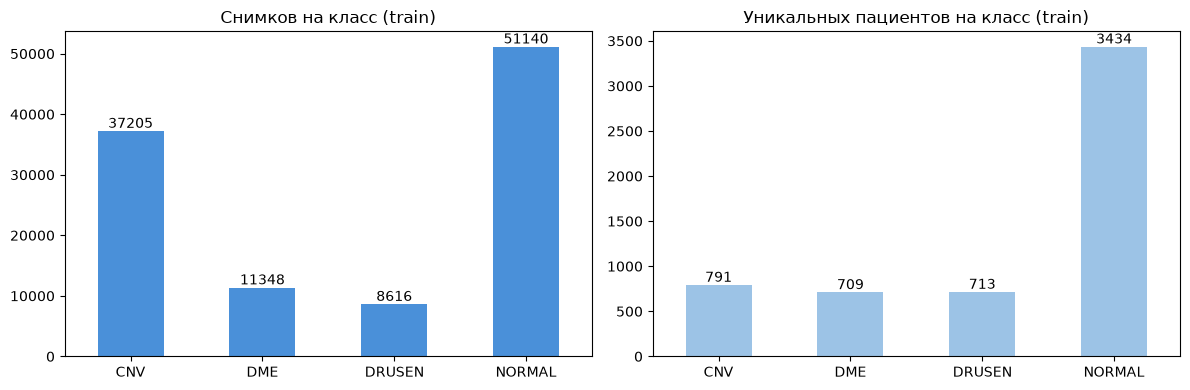

In [7]:
# График баланса классов -> reports/figures/class_balance.png
import matplotlib.pyplot as plt

config.FIGURES.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
img["train"].plot.bar(ax=ax[0], color="#4A90D9")
ax[0].set_title("Снимков на класс (train)")
pat["train"].plot.bar(ax=ax[1], color="#9CC3E6")
ax[1].set_title("Уникальных пациентов на класс (train)")
for a in ax:
    a.set_xlabel("")
    a.tick_params(axis="x", rotation=0)
    for c in a.containers:
        a.bar_label(c)
plt.tight_layout()
plt.savefig(config.FIGURES / "class_balance.png", dpi=150)
plt.show()

## 4. Битые файлы и дубли

**Хеши и полная проверка файлов.** Для каждого снимка: полностью раскодирует изображение (находит битые файлы), считает MD5 (точные копии) и perceptual hash (визуально одинаковые снимки). Хеши сохраняются в `data/hashes.csv` (в git не попадает). Занимает около 10 мин.

Обработка идёт параллельно на всех ядрах. В Linux и Colab — процессами; в Windows — потоками, потому что в Windows дочерние процессы не видят функции, объявленные в ноутбуке.

In [8]:
# Полная проверка файлов, MD5 и perceptual hash для всех снимков
import io, os, hashlib
import imagehash
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor

def scan(rel):
    """
    Полностью раскодирует снимок и считает его хеши.
    rel — путь к снимку относительно config.DATA_OCT
    Возвращает кортеж (rel, md5, phash, error):
    md5 — хеш байтов файла (совпадает только у точных копий)
    phash — перцептивный хеш (совпадает у визуально одинаковых снимков)
    error — текст ошибки, если файл не удалось раскодировать, иначе ""
    """
    try:
        data = (root / rel).read_bytes()
        md5 = hashlib.md5(data).hexdigest()
        with Image.open(io.BytesIO(data)) as im:
            im.load()  # полная декодировка: битый или обрезанный JPEG вызовет ошибку
            ph = str(imagehash.phash(im.convert("L")))
        return rel, md5, ph, ""
    except Exception as e:
        return rel, None, None, repr(e)

# Параллельная обработка на всех ядрах: в Windows потоками (процессы не видят
# функцию scan из ноутбука), в Linux и Colab процессами (быстрее)
Pool = ThreadPoolExecutor if os.name == "nt" else ProcessPoolExecutor
with Pool(os.cpu_count()) as ex:
    res = list(tqdm(ex.map(scan, df["path"], chunksize=256), total=len(df)))

h = pd.DataFrame(res, columns=["path", "md5", "phash", "error"])
df = df.drop(columns=["md5", "phash", "error"], errors="ignore").merge(h, on="path")
h.to_csv(config.HASHES, index=False)
print("Проверено:", len(h), "| ошибок чтения:", (h["error"] != "").sum())

  0%|          | 0/109309 [00:00<?, ?it/s]

  0%|          | 1/109309 [00:04<122:20:46,  4.03s/it]

  0%|          | 51/109309 [00:04<1:44:56, 17.35it/s] 

  0%|          | 93/109309 [00:04<50:37, 35.96it/s]  

  0%|          | 127/109309 [00:04<33:23, 54.50it/s]

  0%|          | 164/109309 [00:04<22:47, 79.82it/s]

... (2,229 outputs left out)

100%|█████████▉| 109260/109309 [04:07<00:00, 452.24it/s]

100%|█████████▉| 109306/109309 [04:08<00:00, 406.97it/s]

100%|██████████| 109309/109309 [04:08<00:00, 440.60it/s]

Проверено: 109309 | ошибок чтения: 0


**Отчёт по дублям.** Выводит битые файлы (если есть) и сводку по группам дублей для MD5 и phash: сколько групп с разными метками, с разными пациентами и попадающих одновременно в train и test.

In [9]:
# Сводка по битым файлам и группам дублей (MD5 и phash)
def dup_report(key):
    """
    Печатает сводку по группам дублей и возвращает снимки-дубли.
    key — колонка с хешем: "md5" (точные копии) или "phash" (визуальные дубли)
    Печатает число групп, файлов и лишних копий, а также сколько групп
    содержат разные метки, разных пациентов и обе выборки (train и test).
    Возвращает DataFrame со снимками, хеш которых встречается больше одного раза,
    отсортированный по хешу.
    """
    d = df[df.duplicated(key, keep=False)]
    s = d.groupby(key).agg(n=("path", "size"),
                           labels=("label", "nunique"),
                           patients=("patient_id", "nunique"),
                           splits=("split", "nunique"))
    print(f"[{key}] групп: {len(s)}, файлов: {s['n'].sum()}, лишних копий: {s['n'].sum() - len(s)}")
    print(f"   разные метки: {(s['labels'] > 1).sum()} | разные пациенты: {(s['patients'] > 1).sum()} "
          f"| train и test: {(s['splits'] > 1).sum()}")
    return d.sort_values(key)

print(df.loc[df["error"] != "", ["path", "error"]], "\n")
dup_md5 = dup_report("md5")
dup_ph = dup_report("phash")
dup_ph[["path", "label", "patient_id", "split", "phash"]].head(10)

Empty DataFrame
Columns: [path, error]
Index: [] 

[md5] групп: 7092, файлов: 14958, лишних копий: 7866
   разные метки: 269 | разные пациенты: 19 | train и test: 0


[phash] групп: 7823, файлов: 16737, лишних копий: 8914
   разные метки: 338 | разные пациенты: 72 | train и test: 0


,path,label,patient_id,split,phash
30474,train/CNV/CNV-8184974-150.jpeg,CNV,8184974,train,800c2f57f5278f5c
30475,train/CNV/CNV-8184974-151.jpeg,CNV,8184974,train,800c2f57f5278f5c
32103,train/CNV/CNV-8796318-32.jpeg,CNV,8796318,train,802679d9b6a3c95e
32102,train/CNV/CNV-8796318-31.jpeg,CNV,8796318,train,802679d9b6a3c95e
5316,train/CNV/CNV-1699976-203.jpeg,CNV,1699976,train,802a55d52f4ad5af
5318,train/CNV/CNV-1699976-205.jpeg,CNV,1699976,train,802a55d52f4ad5af
5321,train/CNV/CNV-1699976-208.jpeg,CNV,1699976,train,802a55d52f4ad5af
5320,train/CNV/CNV-1699976-207.jpeg,CNV,1699976,train,802a55d52f4ad5af
5319,train/CNV/CNV-1699976-206.jpeg,CNV,1699976,train,802a55d52f4ad5af
5317,train/CNV/CNV-1699976-204.jpeg,CNV,1699976,train,802a55d52f4ad5af


**Визуальная проверка.** Какие пары классов встречаются у точных копий с разными метками, и по 4 случайных примера: точные копии с разными метками и визуальные дубли (одинаковый phash, разные байты). Нужна, чтобы убедиться, что phash не даёт ложных совпадений, и выбрать правило очистки.

md5-групп с разными метками: 269 | phash-групп с разными md5: 935
label
CNV + DRUSEN       187
DRUSEN + NORMAL     53
CNV + DME           21
DME + NORMAL         8
Name: count, dtype: int64


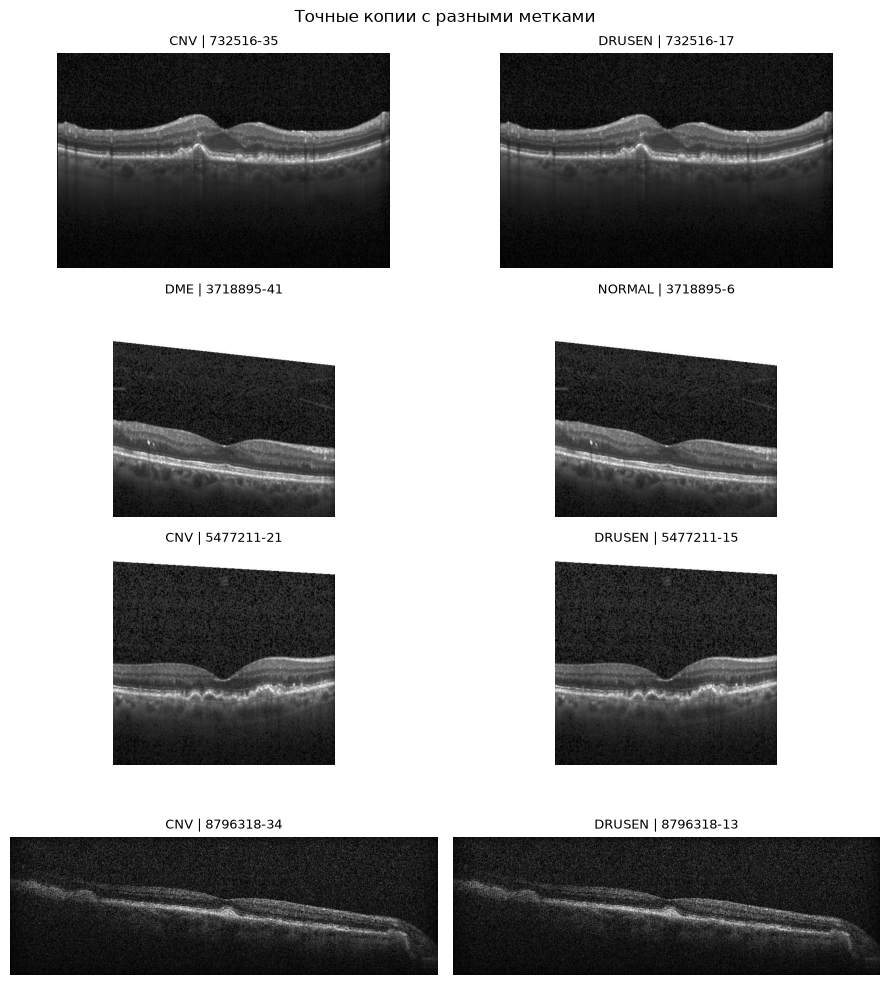

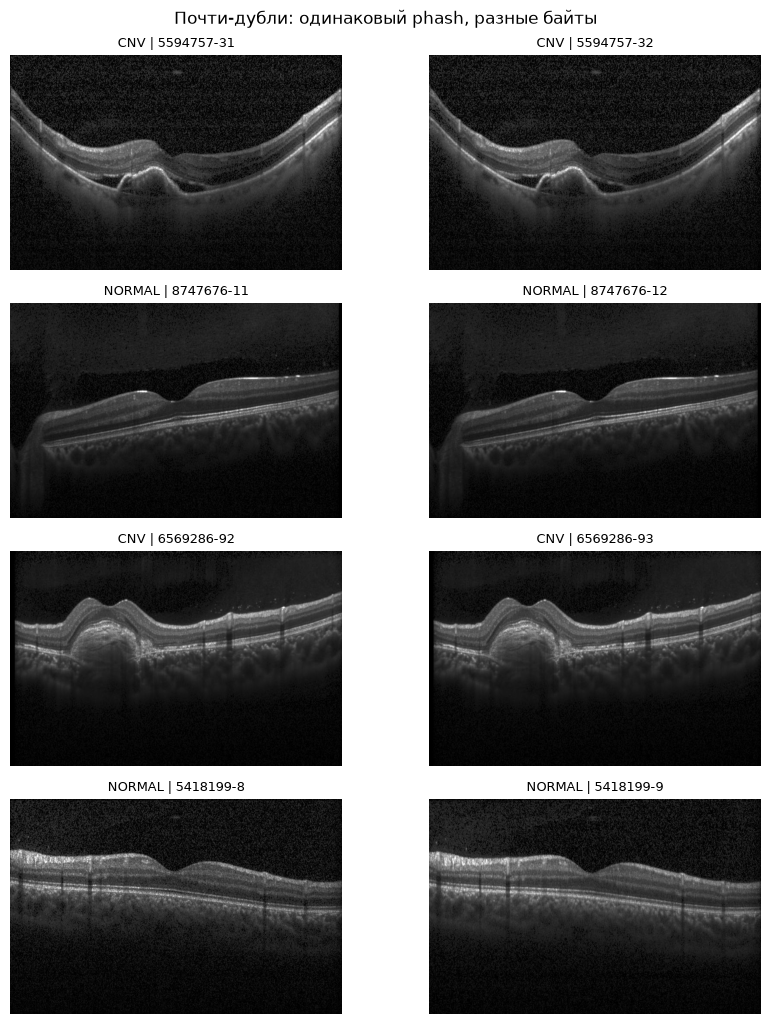

In [10]:
# Визуальная проверка групп дублей
import random

# conf — точные копии (одинаковый MD5) с разными метками
dup = df[df.duplicated("md5", keep=False)]
conf = [k for k, x in dup.groupby("md5") if x["label"].nunique() > 1]
# near — визуальные дубли: одинаковый phash, но разные байты
near = [k for k, x in df[df.duplicated("phash", keep=False)].groupby("phash")
        if x["md5"].nunique() > 1]
print("md5-групп с разными метками:", len(conf), "| phash-групп с разными md5:", len(near))
print(df[df["md5"].isin(conf)].groupby("md5")["label"]
      .agg(lambda s: " + ".join(sorted(s.unique()))).value_counts())

def show(groups, key, title, n=4):
    """
    Показывает по два снимка из n случайных групп дублей.
    groups — список значений хеша (групп), из которых выбирать
    key — колонка хеша: "md5" или "phash"
    title — заголовок рисунка
    n — сколько групп показать; выбор воспроизводим (config.SEED)
    В подписи к снимку: класс | ID пациента-номер снимка.
    """
    pick = random.Random(config.SEED).sample(groups, min(n, len(groups)))
    fig, ax = plt.subplots(len(pick), 2, figsize=(9, 2.6 * len(pick)))
    for i, k in enumerate(pick):
        for j, (_, r) in enumerate(df[df[key] == k].head(2).iterrows()):
            ax[i, j].imshow(Image.open(root / r["path"]), cmap="gray")
            ax[i, j].set_title(f"{r['label']} | {r['patient_id']}-{r['img_num']}", fontsize=9)
    for a in ax.ravel():
        a.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show(conf, "md5", "Точные копии с разными метками")
show(near, "phash", "Почти-дубли: одинаковый phash, разные байты")

## 5. Очистка train

Правило по результатам п. 4 (применяется только к train; официальный test не меняется, чтобы результаты были сравнимы со статьями):
- группа визуальных дублей с **одной** меткой — оставляем один снимок, остальные помечаем `duplicate`;
- группа с **разными** метками — исключаем целиком, пометка `conflict_label`.

Точные копии всегда имеют одинаковый phash, поэтому одно правило покрывает оба вида дублей. Ячейка выводит число исключённых снимков и классы до/после очистки.

In [11]:
# Очистка train от дублей и противоречивых меток
# Сортировка: в каждой группе первым идёт снимок с меньшим номером — его и оставляем
df = df.sort_values(["phash", "patient_id", "img_num"]).reset_index(drop=True)
tr = df["split"] == "train"
n_lab = df.groupby("phash")["label"].transform("nunique")
first = ~df.duplicated("phash")

# Правило очистки (только train): группа с разными метками -> исключить целиком,
# группа с одной меткой -> оставить первый снимок
df["reason"] = ""
df.loc[tr & (n_lab > 1), "reason"] = "conflict_label"
df.loc[tr & (n_lab == 1) & ~first, "reason"] = "duplicate"

print(df.loc[tr, "reason"].replace("", "keep").value_counts())
print("Дублей внутри test (не трогаем):", df[~tr].duplicated("phash", keep=False).sum())
clean = df[tr & (df["reason"] == "")]
print(pd.DataFrame({"было": df[tr]["label"].value_counts(),
                    "стало": clean["label"].value_counts()}))

reason
keep              99082
duplicate          8525
conflict_label      702
Name: count, dtype: int64
Дублей внутри test (не трогаем): 50
         было  стало
label               
NORMAL  51140  49649
CNV     37205  31033
DME     11348  10671
DRUSEN   8616   7729


## 6. Разбиение train / val / test

Val выделяется из очищенного train **по пациентам** (`StratifiedGroupKFold`): все снимки одного пациента попадают в одну выборку. Из 50 вариантов (5 seed × 10 фолдов) выбирается тот, где доли классов в val ближе всего к train. Test — официальный (1 000 снимков, по 250 на класс).

Ячейка проверяет отсутствие общих пациентов и phash между выборками и сохраняет `data/splits.csv` (колонки: `path`, `split`, `label`, `patient_id`, `reason`).

**Как читать разбиение:**
```python
s = pd.read_csv(config.SPLITS, dtype={"patient_id": str})
train = s[s["split"] == "train"]   # также "val", "test"; "excluded" не использовать
```

In [12]:
# Разбиение по пациентам, проверка утечки и сохранение data/splits.csv
from sklearn.model_selection import StratifiedGroupKFold

# 1. Подбор val: 5 seed × 10 фолдов, берём фолд (~10%) с самыми близкими к train долями классов
target = clean["label"].value_counts(normalize=True)
best = None
for seed in range(5):
    sg = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=seed)
    for k, (_, vi) in enumerate(sg.split(clean, clean["label"], clean["patient_id"])):
        if not 0.08 < len(vi) / len(clean) < 0.12:
            continue
        dev = (clean.iloc[vi]["label"].value_counts(normalize=True) - target).abs().max()
        if best is None or dev < best[0]:
            best = (dev, seed, k, vi)

dev, seed, k, val_idx = best
print(f"Выбран seed={seed}, fold={k}: макс. отклонение {dev * 100:.1f} п.п., "
      f"val = {len(val_idx)} ({len(val_idx) / len(clean):.1%})")
val_ids = set(clean.iloc[val_idx]["patient_id"])

# 2. Разметка выборок: train / val / test / excluded
keep = tr & (df["reason"] == "")
df["new_split"] = "excluded"
df.loc[~tr, "new_split"] = "test"
df.loc[keep, "new_split"] = "train"
df.loc[keep & df["patient_id"].isin(val_ids), "new_split"] = "val"

# 3. Проверка утечки: общих пациентов и phash между выборками быть не должно
S = ["train", "val", "test"]
pid = {s: set(df.loc[df["new_split"] == s, "patient_id"]) for s in S}
ph = {s: set(df.loc[df["new_split"] == s, "phash"]) for s in S}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"{a}∩{b}: пациентов {len(pid[a] & pid[b])}, phash {len(ph[a] & ph[b])}")

# 4. Число снимков и доли классов по выборкам
print(pd.crosstab(df["label"], df["new_split"], margins=True))
print((pd.crosstab(df["label"], df["new_split"], normalize="columns") * 100).round(1))

# 5. Сохранение итогового разбиения в data/splits.csv
out = (df[["path", "new_split", "label", "patient_id", "reason"]]
       .rename(columns={"new_split": "split"}).sort_values("path"))
out.to_csv(config.SPLITS, index=False)
print("Сохранено:", config.SPLITS, out.shape)

Выбран seed=0, fold=4: макс. отклонение 0.0 п.п., val = 9908 (10.0%)


train∩val: пациентов 0, phash 0
train∩test: пациентов 0, phash 0
val∩test: пациентов 0, phash 0
new_split  excluded  test  train   val     All
label                                         
CNV            6172   250  27930  3103   37455
DME             677   250   9604  1067   11598
DRUSEN          887   250   6956   773    8866
NORMAL         1491   250  44684  4965   51390
All            9227  1000  89174  9908  109309


new_split  excluded  test  train   val
label                                 
CNV            66.9  25.0   31.3  31.3
DME             7.3  25.0   10.8  10.8
DRUSEN          9.6  25.0    7.8   7.8
NORMAL         16.2  25.0   50.1  50.1


Сохранено: D:\projects\12-medical-image-analysis\data\splits.csv (109309, 5)


## Выводы по данным (Виталий)

**Источник.** Kermany et al., Mendeley Data v3.

**Объём.** 109 309 снимков: train 108 309, test 1 000 (по 250 на класс). Битых файлов нет (полная декодировка всех снимков).

**Баланс.** В train NORMAL 47,2%, CNV 34,4%, DME 10,5%, DRUSEN 8,0%; дисбаланс 5,9 раза (после очистки — 6,4). По числу пациентов три класса болезней почти равны (709–791), дисбаланс снимков создают в основном пациенты с CNV (≈47 снимков на пациента против 12–16 в других классах).

**Пациенты.** 5 420 уникальных ID; пересечений train/test по ID нет. Снимков на пациента: медиана 10, максимум 813. У 787 пациентов несколько диагнозов.

**Дубли.** MD5: 7 866 точных копий; phash: 8 914 визуально одинаковых снимков (соседние B-сканы одного пациента). 269 групп точных копий имеют разные метки (чаще CNV + DRUSEN). Между train и test дублей нет.

**Очистка train.** Исключено 9 227 снимков (8,5%): 8 525 дублей (оставлен один снимок из группы) и 702 снимка с противоречивыми метками.

**Разбиение (`data/splits.csv`).** train 89 174 / val 9 908 / test 1 000. Val выделен из train по пациентам (StratifiedGroupKFold, выбран вариант seed=0, fold=4; доли классов в val и train совпадают с точностью до 0,01 п.п.). Подбор зависит от версии scikit-learn, поэтому версии закреплены в `uv.lock` (scikit-learn 1.9.1). До перехода на uv (scikit-learn 1.6.1) получалось train 88 548 / val 10 534. Общих пациентов и phash между выборками нет.

**Ограничения.** Наш подсчёт ID (5 420: train 4 785, test 635) немного расходится с Tampu et al., 2022 (5 319: 4 686 и 633); пересечений train/test по ID нет в обоих подсчётах. В test 50 файлов входят в группы дублей. Два снимка test/DRUSEN цветные (RGB) и нестандартного размера.

**Рекомендации команде.** Использовать только `splits.csv`; метрика — macro-F1; взвешенный loss или балансирующий сэмплер; привести все снимки к режиму L.